# Sistema de detección de enfermedades en hojas de maíz con técnicas de IA
### Versión 5 (final) — justificación completa de la arquitectura de transferencia

**ESPOL — FIEC — Inteligencia Artificial · Grupo #1**
Ariana Palacios · Carlos Flores · Julio Guerrero

---

Esta versión responde de forma explícita a las **cuatro correcciones exigidas por el profesor
para la entrega final**. Cada una tiene su celda de justificación y su evidencia en código:

| Corrección del profesor | Sección que la responde | Evidencia en código |
|---|---|---|
| **1. Justificar la arquitectura base** de transferencia | §4 + §12 (baseline) | `construir_modelo`, comparación contra CNN desde cero |
| **2. Qué capas se congelan** | §6 | Fase 1: backbone completo congelado |
| **3. Qué capas se reentrenan** | §7 + §13 (búsqueda) | `descongelar_ultimos_bloques` (últimos 3 bloques, por nombre) |
| **4. Cómo se evita la "caja negra"** | §11 | `gradcam_mapa` / `gradcam_superponer` (explicabilidad visual) |

**Origen de esta versión.** Fusiona lo mejor de las dos ramas del equipo: la base metodológica
de la v3 (entrenamiento en dos fases, descongelamiento por nombre, BatchNorm congelada,
Grad-CAM) y los dos aportes empíricos de la v4 (un *baseline* sin transferencia y una búsqueda
de hiperparámetros) — esta última **corregida** para seleccionar por validación y no por el
conjunto de prueba.

## 1. Importación de librerías y verificación de GPU

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

print('TensorFlow', tf.__version__)

device_name = tf.test.gpu_device_name()
if device_name != '/device:GPU:0':
    print('ADVERTENCIA: GPU no encontrada. Activa el entorno por GPU en Colab '
          '(Entorno de ejecución -> Cambiar tipo de entorno de ejecución -> GPU).')
else:
    print('GPU detectada y activa:', device_name)

TensorFlow 2.20.0
GPU detectada y activa: /device:GPU:0


También es necesario montar el drive para poder cargar las imágenes.

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


## 2. Configuración global

Todos los hiperparámetros comprometidos en el documento quedan centralizados aquí, para que la
trazabilidad **documento ↔ código** sea verificable de un vistazo.

In [ ]:
DATASET_DIR = '/content/drive/MyDrive/ESPOL/IA/Proyecto/CornLeafDiseaseCollection'
RUTA_METADATOS = os.path.join(DATASET_DIR, 'Data.csv')
RUTA_MODELO = 'best_maize_model_v5.keras'

SEED = 42
keras.utils.set_random_seed(SEED)   # reproducibilidad: misma partición y misma inicialización

# --- Dataset ---
IMG_SIZE = (224, 224)
BATCH_SIZE = 32                       # documento: 32 imágenes por lote
CLASSES = ['healthy', 'stenocarpella', 'bipolaris', 'common_rust', 'asphalt_stain']
NUM_CLASSES = len(CLASSES)
NOMBRES_VISIBLES = {'healthy': 'Healthy', 'stenocarpella': 'Stenocarpella',
                    'bipolaris': 'Bipolaris', 'common_rust': 'Common Rust',
                    'asphalt_stain': 'Asphalt Stain'}

# --- Entrenamiento en dos fases ---
LR_FASE1 = 1e-4                       # documento: tasa de aprendizaje 0.0001
LR_FASE2 = 1e-5                       # documento: "una tasa de aprendizaje menor"
EPOCHS_FASE1 = 10                     # documento: "durante 10 épocas"
EPOCHS_FASE2 = 30                     # documento: 30 épocas
PATIENCE = 5                          # documento: parada temprana, paciencia 5
FINE_TUNE_DESDE_BLOQUE = 14           # documento: "los últimos 3 bloques" (block_14/15/16 + Conv_1)

# --- Opciones ---
AUGMENT_EXTRA = True                  # brillo/contraste además de flip+rotación+zoom
USE_CLASS_WEIGHTS = True              # compensa el desbalance real del dataset
UMBRAL_BAJA_CONFIANZA = 0.60          # CU-02, escenario 2.2

# --- Estudios empíricos (opcionales; encienden las secciones §12 y §13) ---
EJECUTAR_BASELINE = True              # entrena la CNN sin transferencia (1 entrenamiento)
EJECUTAR_BUSQUEDA = True             # búsqueda de #bloques por validación (varios entrenamientos)
EPOCHS_BUSQUEDA_F1 = 6                # épocas reducidas: es una búsqueda, no el modelo final
EPOCHS_BUSQUEDA_F2 = 15

## 3. Justificación #1 — ¿Por qué *transfer learning* con MobileNetV2?

> **Corrección del profesor:** *justificar la arquitectura base que usan para transferencia.*

**Por qué transferencia y no entrenar desde cero.** El dataset tiene **1 079 imágenes**, un
volumen pequeño para visión por computador. Una red profunda entrenada desde cero sobre tan
pocos datos memoriza (sobreajuste) en lugar de generalizar. El *transfer learning* reutiliza
los filtros de bajo nivel (bordes, texturas, gradientes de color) que una red ya aprendió sobre
los **1,2 millones de imágenes de ImageNet**; esos filtros son genéricos y transferibles a la
identificación de lesiones en tejido foliar. La §12 lo demuestra empíricamente: una CNN
equivalente entrenada desde cero se queda muy por debajo.

**Por qué MobileNetV2 en concreto** (y no ResNet50, VGG16, EfficientNet…):

1. **Eficiencia y bajo riesgo de sobreajuste.** Sus *convoluciones separables en profundidad*
   la hacen ligera (~2,3 M de parámetros, frente a ~25 M de ResNet50). Con solo ~1 000 imágenes,
   una red más pesada tendría demasiada capacidad y sobreajustaría; MobileNetV2 ofrece un
   equilibrio adecuado entre capacidad y tamaño de datos.
2. **Despliegue realista.** El usuario objetivo del proyecto es el pequeño productor con un
   teléfono. MobileNetV2 fue diseñada para dispositivos móviles: poca memoria y baja latencia,
   fácil de integrar en la app o en un microservicio en la nube.
3. **Transferibilidad probada.** Sus *bloques residuales invertidos* preservan la información en
   los cuellos de botella, y sus características de ImageNet transfieren bien a dominios de hojas
   y plantas (ampliamente documentado en la literatura de *plant disease detection*).

## 4. Carga de datos, metadatos (`Data.csv`) y partición estratificada 70 / 15 / 15

In [ ]:
filepaths, labels = [], []
for idx_clase, nombre_clase in enumerate(CLASSES):
    dir_clase = os.path.join(DATASET_DIR, nombre_clase)
    if not os.path.isdir(dir_clase):
        raise FileNotFoundError('No existe el subdirectorio de clase: %s' % dir_clase)
    for fname in sorted(os.listdir(dir_clase)):
        if fname.lower().endswith(('.png', '.jpg', '.jpeg')):
            filepaths.append(os.path.join(dir_clase, fname))
            labels.append(idx_clase)

df = pd.DataFrame({'filepath': filepaths, 'label': labels})
print('Total de imágenes encontradas:', len(df))

# El Data.csv del repositorio de origen usa ';' como separador; sep=None deja que pandas lo
# detecte y evita que se cargue como una sola columna.
if os.path.exists(RUTA_METADATOS):
    metadatos = pd.read_csv(RUTA_METADATOS, sep=None, engine='python')
    print('Data.csv cargado:', metadatos.shape[0], 'filas,', metadatos.shape[1], 'columnas')
    if 'multiclass_label' in metadatos.columns:
        print('\nDistribución declarada en los metadatos:')
        print(metadatos['multiclass_label'].value_counts())
else:
    metadatos = None
    print('Data.csv no encontrado; se continúa con el inventario por subdirectorios.')

# Auditoría: el documento declara 200 imágenes por clase (1 000 en total)
print('\nComposición real del dataset:')
for i, n in df['label'].value_counts().sort_index().items():
    print('  %-16s %4d imágenes  (documento: 200)' % (CLASSES[i], n))
if len(df) != 1000:
    print('\nAVISO: hay %d imágenes (no 1 000) y las clases están desbalanceadas. '
          'El desbalance se compensa con pesos de clase (§5).' % len(df))

Total de imágenes encontradas: 1079
Data.csv cargado: 1080 filas, 13 columnas

Distribución declarada en los metadatos:
multiclass_label
healthy          232
stenocarpella    227
bipolaris        220
common_rust      200
asphalt_stain    200
Name: count, dtype: int64

Composición real del dataset:
  healthy           232 imágenes  (documento: 200)
  stenocarpella     227 imágenes  (documento: 200)
  bipolaris         220 imágenes  (documento: 200)
  common_rust       200 imágenes  (documento: 200)
  asphalt_stain     200 imágenes  (documento: 200)

AVISO: hay 1079 imágenes (no 1 000) y las clases están desbalanceadas. El desbalance se compensa con pesos de clase (§5).


In [ ]:
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=SEED,
                                      stratify=df['label'])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED,
                                    stratify=temp_df['label'])
print('Entrenamiento (70%%): %d | Validación (15%%): %d | Prueba (15%%): %d'
      % (len(train_df), len(val_df), len(test_df)))

Entrenamiento (70%): 755 | Validación (15%): 162 | Prueba (15%): 162


## 5. Generadores `tf.data`

Tres decisiones y su porqué:

1. **`tf.io.decode_image`** (no `decode_jpeg`): el inventario admite PNG y es el mismo
   decodificador que usa la app Streamlit → el preprocesamiento de entrenamiento e inferencia
   coincide exactamente.
2. **Etiquetas one-hot + `CategoricalCrossentropy`**, tal como pide el documento.
3. El desbalance se compensa con **`sample_weight`** dentro del `tf.data` (el `class_weight` de
   Keras es incompatible con etiquetas one-hot). Los pesos se calculan **solo con el training
   set**, nunca con validación/prueba, para no filtrar información.

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

pesos_array = (compute_class_weight('balanced', classes=np.arange(NUM_CLASSES),
                                    y=train_df['label'].values)
               if USE_CLASS_WEIGHTS else np.ones(NUM_CLASSES))
TABLA_PESOS = tf.constant(pesos_array, dtype=tf.float32)
print('Pesos de clase (solo training set):')
for i, p in enumerate(pesos_array):
    print('  %-16s %.3f' % (CLASSES[i], p))


def _cargar(ruta, etiqueta):
    img = tf.io.decode_image(tf.io.read_file(ruta), channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    return img, tf.one_hot(etiqueta, NUM_CLASSES)


def _con_peso(img, etiqueta):
    return img, etiqueta, tf.gather(TABLA_PESOS, tf.argmax(etiqueta))


def build_dataset(df_subset, is_training=False):
    ds = tf.data.Dataset.from_tensor_slices((df_subset['filepath'].values,
                                             df_subset['label'].values))
    if is_training:
        ds = ds.shuffle(len(df_subset), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(_cargar, num_parallel_calls=AUTOTUNE)
    if is_training:
        ds = ds.map(_con_peso, num_parallel_calls=AUTOTUNE).repeat()
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = build_dataset(train_df, is_training=True)
val_ds = build_dataset(val_df)
test_ds = build_dataset(test_df)
STEPS_POR_EPOCA = int(np.ceil(len(train_df) / BATCH_SIZE))
print('\nPasos por época:', STEPS_POR_EPOCA)

Pesos de clase (solo training set):
  healthy          0.932
  stenocarpella    0.950
  bipolaris        0.981
  common_rust      1.079
  asphalt_stain    1.079

Pasos por época: 24


## 6. Justificación #2 y #3 — Qué se congela, qué se reentrena y por qué

> **Corrección del profesor:** *qué capas congelarán, cuáles reentrenarán.*

Se usa la estrategia clásica de **dos fases**, que es exactamente la que describe el documento:

**Fase 1 — Extracción de características (backbone 100 % congelado).**
Se congelan las 154 capas de MobileNetV2 y se entrena **solo la cabeza** (≈ 165 k parámetros).
*Por qué:* la cabeza se inicializa al azar y produce gradientes grandes; si el backbone
estuviera activo, esos gradientes **destruirían** los pesos preentrenados de ImageNet antes de
que la cabeza aprenda nada útil. Primero se estabiliza la cabeza (10 épocas, lr 1e-4).

**Fase 2 — Ajuste fino (se liberan los últimos 3 bloques).**
Se descongelan `block_14`, `block_15`, `block_16` y el `Conv_1` final; **las primeras ~117
capas siguen congeladas**.
*Por qué solo los últimos bloques:* en una CNN las capas iniciales aprenden características
**genéricas** (bordes, texturas, color) que sirven a cualquier dominio → conviene conservarlas.
Las capas profundas aprenden características **específicas de ImageNet** (objetos cotidianos)
→ se readaptan a la morfología de las lesiones fúngicas del maíz. Reentrenar también las
primeras capas desperdiciaría la transferencia y, con tan pocos datos, provocaría sobreajuste.

**Por qué se seleccionan por NOMBRE (`block_14…`) y no contando capas.** El nombre identifica
el bloque de forma exacta y legible; contar "las últimas 30 capas" es frágil y puede partir un
bloque por la mitad, dejando fuera capas que deberían ir juntas.

**Por qué las BatchNormalization quedan congeladas incluso en la Fase 2.** Sus estadísticas
(media/varianza móviles) se estimaron sobre millones de imágenes de ImageNet. Reestimarlas con
lotes de solo 32 imágenes inyecta ruido y desestabiliza el ajuste — es una práctica estándar
del *fine-tuning* mantenerlas en modo inferencia.

## 7. Arquitectura del modelo

La cabeza sigue literalmente el documento: **reducción espacial → regularización → capa densa
con activación ReLU → capa de salida Softmax**. El preprocesamiento de MobileNetV2 (reescalado
a `[-1, 1]`) viaja **dentro** del modelo como una capa `Rescaling`, de modo que la app no tiene
que normalizar por su cuenta.

In [ ]:
def crear_augmentation():
    """Data augmentation on-the-fly. Las tres primeras transformaciones son las exigidas
    por el documento (volteo, rotacion +/-20, zoom 0.8-1.2). Brillo y contraste se agregan
    porque la seccion 'Resultados' pide que el modelo ignore variaciones de iluminacion de
    las capturas con telefono."""
    capas = [
        layers.RandomFlip('horizontal', seed=SEED),
        layers.RandomRotation(factor=20/360, fill_mode='reflect', seed=SEED),  # +/-20 grados
        layers.RandomZoom(height_factor=(-0.2, 0.2), width_factor=(-0.2, 0.2),
                          fill_mode='reflect', seed=SEED),                     # zoom 0.8-1.2
    ]
    if AUGMENT_EXTRA:
        capas += [layers.RandomBrightness(factor=0.2, value_range=(0, 255), seed=SEED),
                  layers.RandomContrast(factor=0.2, seed=SEED)]
    return keras.Sequential(capas, name='data_augmentation')


def construir_modelo(lr=LR_FASE1):
    """Ensambla MobileNetV2 (congelada) + la cabeza clasificadora descrita en el documento:
    reduccion espacial -> regularizacion -> capa densa ReLU -> capa Softmax de 5 clases.
    Devuelve el modelo YA compilado para la Fase 1 (backbone congelado)."""
    data_augmentation = crear_augmentation()

    base_model = keras.applications.MobileNetV2(
        input_shape=(*IMG_SIZE, 3), include_top=False, weights='imagenet')
    base_model.trainable = False   # FASE 1: backbone completamente congelado

    inputs = keras.Input(shape=(*IMG_SIZE, 3), name='entrada_hoja')
    x = data_augmentation(inputs)
    # Rescaling(1/127.5, -1) == mobilenet_v2.preprocess_input, pero como capa nativa: el
    # preprocesamiento viaja DENTRO del modelo, de modo que la app Streamlit no debe normalizar.
    x = layers.Rescaling(1.0 / 127.5, offset=-1.0, name='preprocesamiento')(x)
    x = base_model(x, training=False)   # training=False: BatchNorm siempre en modo inferencia
    x = layers.GlobalAveragePooling2D(name='reduccion_espacial')(x)
    x = layers.Dropout(0.3, name='regularizacion_1')(x)
    x = layers.Dense(128, activation='relu', name='densa_relu')(x)   # cabeza densa ReLU
    x = layers.Dropout(0.2, name='regularizacion_2')(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='softmax_classifier')(x)

    modelo = keras.Model(inputs, outputs, name='maize_v5')
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                   loss=keras.losses.CategoricalCrossentropy(), metrics=['accuracy'])
    return modelo


model = construir_modelo(lr=LR_FASE1)
model.summary()
n1 = int(sum(np.prod(w.shape) for w in model.trainable_weights))
print('\nFASE 1 — parámetros entrenables: {:,} (solo la cabeza; backbone congelado)'.format(n1))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "maize_v5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ entrada_hoja (InputLayer)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocesamiento (Rescaling)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reduccion_espacial              │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularizacion_1 (Dropout)      │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_relu (Dense)              │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regularizacion_2 (Dropout)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax_classifier (Dense)      │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


FASE 1 — parámetros entrenables: 164,613 (solo la cabeza; backbone congelado)


## 8. Fase 1 — Extracción de características (10 épocas, backbone congelado)

In [ ]:
ckpt_f1 = ModelCheckpoint(RUTA_MODELO, monitor='val_loss', save_best_only=True, verbose=1)
hist_fase1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FASE1,
                       steps_per_epoch=STEPS_POR_EPOCA, callbacks=[ckpt_f1])

Epoch 1/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 11s/step - accuracy: 0.2092 - loss: 2.1074 
Epoch 1: val_loss improved from None to 1.35785, saving model to best_maize_model_v5.keras

Epoch 1: finished saving model to best_maize_model_v5.keras
24/24 ━━━━━━━━━━━━━━━━━━━━ 339s 14s/step - accuracy: 0.2539 - loss: 1.8757 - val_accuracy: 0.4938 - val_loss: 1.3579
Epoch 2/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 443ms/step - accuracy: 0.3862 - loss: 1.4591
Epoch 2: val_loss improved from 1.35785 to 1.04531, saving model to best_maize_model_v5.keras

Epoch 2: finished saving model to best_maize_model_v5.keras
24/24 ━━━━━━━━━━━━━━━━━━━━ 21s 911ms/step - accuracy: 0.4271 - loss: 1.3881 - val_accuracy: 0.6914 - val_loss: 1.0453
Epoch 3/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 481ms/step - accuracy: 0.5397 - loss: 1.1711
Epoch 3: val_loss improved from 1.04531 to 0.90559, saving model to best_maize_model_v5.keras

Epoch 3: finished saving model to best_maize_model_v5.keras
24/24 ━━━━━━━━━━━━━━━━━━━━ 17s 715ms/step - ac

## 9. Fase 2 — Ajuste fino de los últimos 3 bloques

Se definen las utilidades de descongelamiento (selección por nombre + BatchNorm congelada),
se **recompila** con `LR_FASE2 = 1e-5` (sin recompilar, Keras seguiría usando el optimizador y
la tasa de la Fase 1) y se reentrena con parada temprana.

In [ ]:
NOMBRES_CABEZA = ['reduccion_espacial', 'regularizacion_1', 'densa_relu',
                  'regularizacion_2', 'softmax_classifier']


def obtener_backbone(modelo):
    """Devuelve la MobileNetV2 anidada (funciona tambien tras keras.models.load_model)."""
    for capa in modelo.layers:
        if isinstance(capa, keras.Model) and 'mobilenet' in capa.name.lower():
            return capa
    raise ValueError('No se encontro la red base MobileNetV2 dentro del modelo.')


def descongelar_ultimos_bloques(modelo, desde_bloque=FINE_TUNE_DESDE_BLOQUE):
    """FASE 2. Mantiene congeladas las primeras capas (bordes, texturas, color: genericas) y
    libera los ultimos bloques convolucionales profundos, seleccionados POR NOMBRE.
    MobileNetV2 nombra sus bloques block_0 ... block_16; desde_bloque=14 libera block_14,
    block_15, block_16 y el Conv_1 final => 'los ultimos 3 bloques' del documento.
    Las BatchNormalization se dejan congeladas a proposito (ver justificacion)."""
    base = obtener_backbone(modelo)
    base.trainable = True

    liberar = False
    for capa in base.layers:
        if capa.name.startswith('block_%d_' % desde_bloque):
            liberar = True
        if not liberar:
            capa.trainable = False
        elif isinstance(capa, layers.BatchNormalization):
            capa.trainable = False     # no reestimar estadisticas con lotes de 32
        else:
            capa.trainable = True

    liberadas = sum(1 for c in base.layers if c.trainable)
    print('Backbone: %d de %d capas liberadas (resto congelado, BatchNorm incluidas).'
          % (liberadas, len(base.layers)))
    return modelo

In [ ]:
descongelar_ultimos_bloques(model)
model.compile(optimizer=keras.optimizers.Adam(learning_rate=LR_FASE2),
              loss=keras.losses.CategoricalCrossentropy(), metrics=['accuracy'])
n2 = int(sum(np.prod(w.shape) for w in model.trainable_weights))
print('FASE 2 — parámetros entrenables: {:,}'.format(n2))

early_stopping = EarlyStopping(monitor='val_loss', patience=PATIENCE,
                               restore_best_weights=True, verbose=1)
ckpt_f2 = ModelCheckpoint(RUTA_MODELO, monitor='val_loss', save_best_only=True, verbose=1)
hist_fase2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FASE2,
                       steps_per_epoch=STEPS_POR_EPOCA,
                       callbacks=[early_stopping, ckpt_f2])

Backbone: 19 de 154 capas liberadas (resto congelado, BatchNorm incluidas).
FASE 2 — parámetros entrenables: 1,675,333
Epoch 1/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 480ms/step - accuracy: 0.7555 - loss: 0.6464
Epoch 1: val_loss improved from None to 0.45693, saving model to best_maize_model_v5.keras

Epoch 1: finished saving model to best_maize_model_v5.keras
24/24 ━━━━━━━━━━━━━━━━━━━━ 31s 787ms/step - accuracy: 0.7643 - loss: 0.6267 - val_accuracy: 0.8272 - val_loss: 0.4569
Epoch 2/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 465ms/step - accuracy: 0.8133 - loss: 0.5189
Epoch 2: val_loss did not improve from 0.45693
24/24 ━━━━━━━━━━━━━━━━━━━━ 16s 696ms/step - accuracy: 0.8203 - loss: 0.4874 - val_accuracy: 0.8333 - val_loss: 0.4631
Epoch 3/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 391ms/step - accuracy: 0.8075 - loss: 0.5042
Epoch 3: val_loss improved from 0.45693 to 0.42359, saving model to best_maize_model_v5.keras

Epoch 3: finished saving model to best_maize_model_v5.keras
24/24 ━━━━━━━━━━━━━━━━━━━━ 17s 72

## 10. Curvas de entrenamiento (pérdida y accuracy)

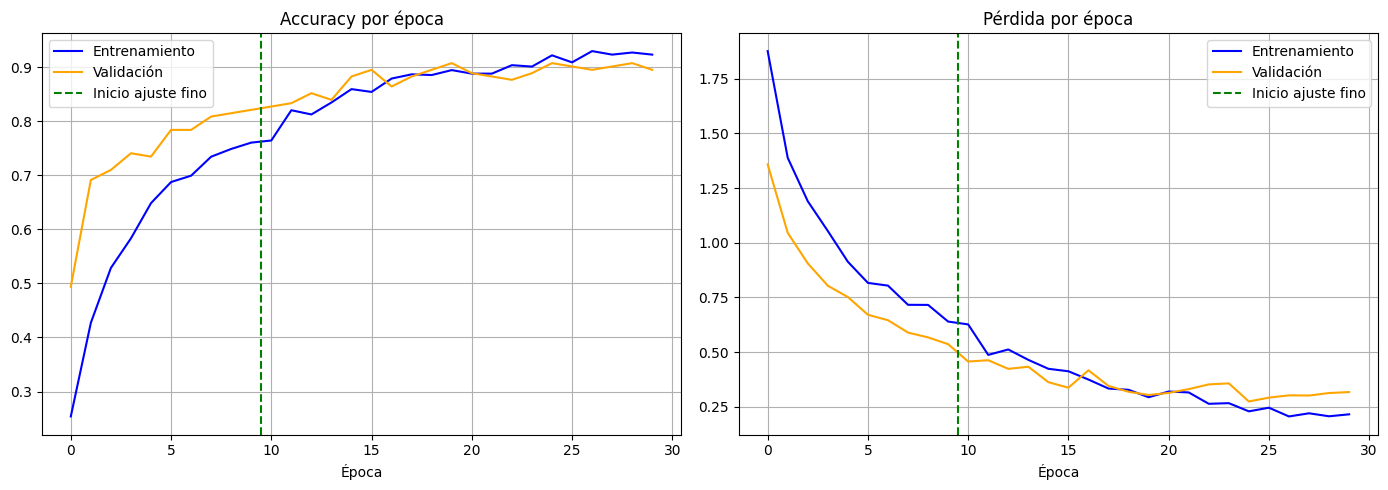

In [ ]:
def unir_historias(*hs):
    u = {}
    for h in hs:
        for k, v in h.history.items():
            u.setdefault(k, []).extend(v)
    return u

hist = unir_historias(hist_fase1, hist_fase2)
corte = len(hist_fase1.history['loss'])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(hist['accuracy'], label='Entrenamiento', color='blue')
ax[0].plot(hist['val_accuracy'], label='Validación', color='orange')
ax[0].axvline(corte - 0.5, color='green', ls='--', label='Inicio ajuste fino')
ax[0].set_title('Accuracy por época'); ax[0].set_xlabel('Época'); ax[0].legend(); ax[0].grid(True)
ax[1].plot(hist['loss'], label='Entrenamiento', color='blue')
ax[1].plot(hist['val_loss'], label='Validación', color='orange')
ax[1].axvline(corte - 0.5, color='green', ls='--', label='Inicio ajuste fino')
ax[1].set_title('Pérdida por época'); ax[1].set_xlabel('Época'); ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.show()

## 11. Evaluación en el Test Set (aislado) y matriz de confusión

=== REPORTE DE CLASIFICACION (TEST SET) ===
               precision    recall  f1-score   support

      healthy     0.9211    1.0000    0.9589        35
stenocarpella     0.9091    0.8824    0.8955        34
    bipolaris     0.8182    0.8182    0.8182        33
  common_rust     0.8056    0.9667    0.8788        30
asphalt_stain     1.0000    0.7333    0.8462        30

     accuracy                         0.8827       162
    macro avg     0.8908    0.8801    0.8795       162
 weighted avg     0.8908    0.8827    0.8812       162



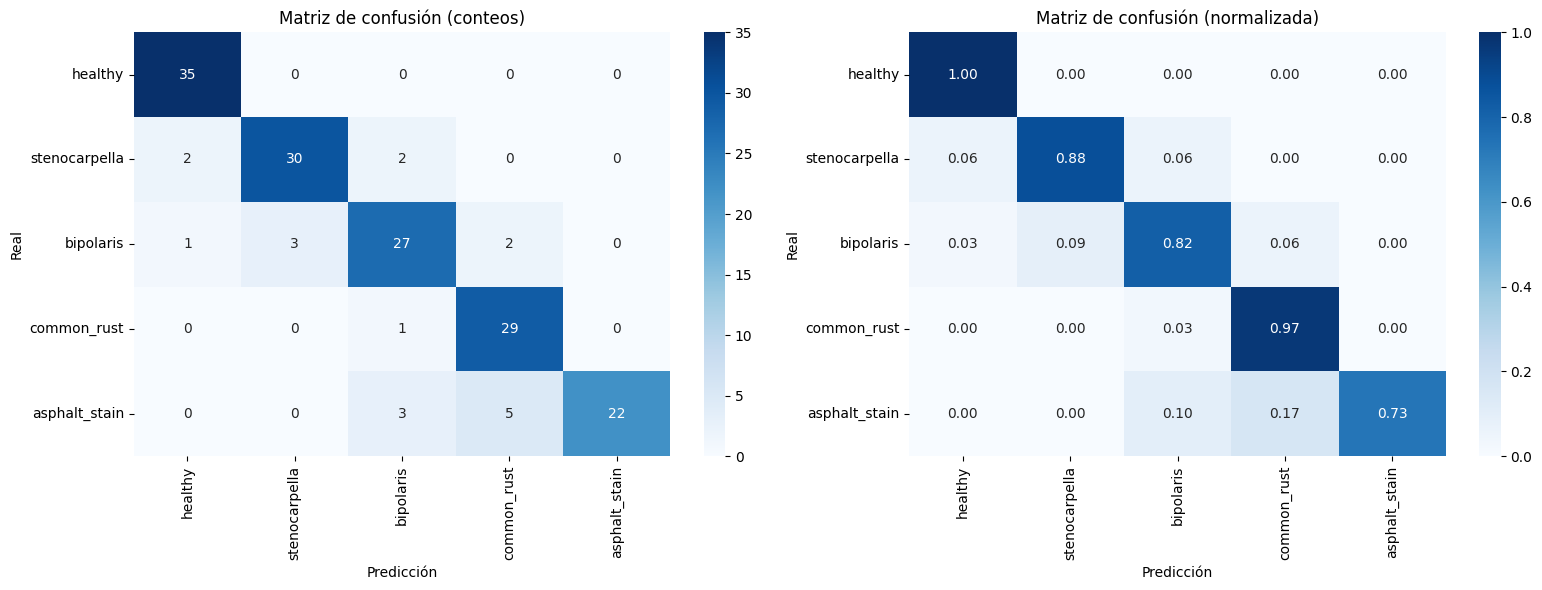

Accuracy global : 88.27%   (meta del documento: > 85%)
F1-Score macro  : 87.95%   (meta del documento: > 85%)
META ALCANZADA.


In [ ]:
def evaluar_en_test(modelo, mostrar=True, titulo='TEST SET'):
    """Evalua un modelo sobre el test set aislado. Devuelve (y_true, y_pred, y_prob, acc, f1)."""
    from sklearn.metrics import accuracy_score, f1_score
    y_true, y_pred, y_prob = [], [], []
    for imagenes, etiquetas in test_ds:
        probs = modelo.predict(imagenes, verbose=0)
        y_true.extend(np.argmax(etiquetas.numpy(), axis=1))
        y_pred.extend(np.argmax(probs, axis=1))
        y_prob.extend(probs)
    y_true, y_pred, y_prob = np.array(y_true), np.array(y_pred), np.array(y_prob)
    acc = accuracy_score(y_true, y_pred)
    f1m = f1_score(y_true, y_pred, average='macro')
    if mostrar:
        print('=== REPORTE DE CLASIFICACION (%s) ===' % titulo)
        print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))
    return y_true, y_pred, y_prob, acc, f1m


y_true, y_pred, y_prob, acc, f1m = evaluar_en_test(model)

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0],
            xticklabels=CLASSES, yticklabels=CLASSES)
ax[0].set_title('Matriz de confusión (conteos)')
ax[0].set_xlabel('Predicción'); ax[0].set_ylabel('Real')
cmn = cm.astype(float) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cmn, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=ax[1],
            xticklabels=CLASSES, yticklabels=CLASSES)
ax[1].set_title('Matriz de confusión (normalizada)')
ax[1].set_xlabel('Predicción'); ax[1].set_ylabel('Real')
plt.tight_layout(); plt.show()

print('Accuracy global : %.2f%%   (meta del documento: > 85%%)' % (acc * 100))
print('F1-Score macro  : %.2f%%   (meta del documento: > 85%%)' % (f1m * 100))
print('META ALCANZADA.' if acc > 0.85 and f1m > 0.85 else 'Meta no alcanzada; ver §12/§13.')

## 12. Justificación #4 — Mitigación de la "caja negra" con Grad-CAM

> **Corrección del profesor:** *cómo evitarán tratar el modelo preentrenado como caja negra.*

Una CNN que solo entrega una etiqueta es una **caja negra**: no sabemos si decidió mirando la
lesión o mirando el fondo, la sombra o algún artefacto de la foto (correlaciones espurias).
**Grad-CAM** abre esa caja:

1. **Mapa de activación de gradiente.** Se calculan los gradientes de la puntuación de la clase
   predicha respecto a los mapas de características de la **última capa convolucional** de la
   red base (`out_relu`). El promedio espacial de esos gradientes da la **importancia de cada
   canal**.
2. **Generación del mapa de calor.** Se hace la suma ponderada de los mapas por esa importancia,
   se aplica ReLU (solo evidencia a favor de la clase) y se normaliza a [0, 1].
3. **Validación agronómica.** Se superpone el mapa sobre la imagen original. Así se **audita
   empíricamente** que la red decide sobre la morfología de las lesiones (manchas, pústulas,
   clorosis) y no sobre el fondo. Si el calor cayera sobre el fondo, sería señal de sesgo del
   dataset y habría que recolectar más muestras.

Esto es, textualmente, "no tratar el modelo como caja negra".

In [ ]:
CAPA_CONV_FINAL = 'out_relu'   # ultima capa convolucional de MobileNetV2


def gradcam_mapa(modelo, imagen_224, indice_clase=None):
    """Grad-CAM: gradiente de la puntuacion de la clase predicha respecto a los mapas de
    caracteristicas de la ultima capa convolucional de la red base."""
    base = obtener_backbone(modelo)
    extractor = keras.Model(base.inputs, base.get_layer(CAPA_CONV_FINAL).output)
    cabeza = [modelo.get_layer(n) for n in NOMBRES_CABEZA]

    x = tf.expand_dims(tf.cast(imagen_224, tf.float32), axis=0)
    x = x / 127.5 - 1.0            # mismo preprocesamiento que la capa 'preprocesamiento'

    with tf.GradientTape() as cinta:
        mapas_conv = extractor(x, training=False)
        cinta.watch(mapas_conv)
        y = mapas_conv
        for capa in cabeza:
            y = capa(y, training=False)
        if indice_clase is None:
            indice_clase = int(tf.argmax(y[0]))
        puntuacion = y[:, indice_clase]

    grads = cinta.gradient(puntuacion, mapas_conv)
    pesos = tf.reduce_mean(grads, axis=(1, 2))                       # importancia por canal
    mapa = tf.reduce_sum(mapas_conv * pesos[:, tf.newaxis, tf.newaxis, :], axis=-1)[0]
    mapa = tf.nn.relu(mapa)                                          # solo evidencia a favor
    mapa = mapa / (tf.reduce_max(mapa) + 1e-8)
    return mapa.numpy(), indice_clase, y[0].numpy()


def gradcam_superponer(mapa, imagen_224, alpha=0.4):
    calor = tf.image.resize(mapa[..., tf.newaxis], IMG_SIZE).numpy()[..., 0]
    fig, ejes = plt.subplots(1, 3, figsize=(13, 4.2))
    ejes[0].imshow(imagen_224.astype('uint8'));       ejes[0].set_title('Captura original')
    ejes[1].imshow(calor, cmap='jet');                ejes[1].set_title('Mapa Grad-CAM')
    ejes[2].imshow(imagen_224.astype('uint8'))
    ejes[2].imshow(calor, cmap='jet', alpha=alpha);   ejes[2].set_title('Superposicion')
    for e in ejes:
        e.axis('off')
    plt.tight_layout()
    return fig

In [ ]:
def _leer_224(ruta):
    img = tf.io.decode_image(tf.io.read_file(ruta), channels=3, expand_animations=False)
    return tf.image.resize(img, IMG_SIZE).numpy()


def auditar_clase(idx_clase, n_aciertos=1, n_errores=1):
    """Muestra el Grad-CAM de aciertos y errores de una clase para la validación agronómica."""
    rutas, reales = test_df['filepath'].values, test_df['label'].values
    mask = reales == idx_clase
    aciertos = np.where(mask & (y_pred == idx_clase))[0][:n_aciertos]
    errores = np.where(mask & (y_pred != idx_clase))[0][:n_errores]
    for i in np.concatenate([aciertos, errores]):
        imagen = _leer_224(rutas[i])
        mapa, idx, probs = gradcam_mapa(model, imagen)
        print('%s — real: %s | predicho: %s (%.1f%%)'
              % ('CORRECTO' if idx == idx_clase else 'ERROR',
                 CLASSES[idx_clase], CLASSES[idx], probs[idx] * 100))
        gradcam_superponer(mapa, imagen); plt.show()

# Ejemplo de auditoría visual de una clase:
# auditar_clase(CLASSES.index('bipolaris'))

## 13. Evidencia empírica del punto #1 — *baseline* sin transferencia

Para **justificar con números** (y no solo con teoría) la elección de MobileNetV2, se entrena
una CNN pequeña **desde cero**, con los mismos datos, augmentación y pesos de clase. Si rinde
mucho peor, queda demostrado el valor del *transfer learning*. Se controla con la bandera
`EJECUTAR_BASELINE`.

In [ ]:
def construir_baseline_cnn():
    """CNN pequena entrenada DESDE CERO (sin ImageNet). Sirve de control: si una red sin
    transferencia rinde mucho peor, queda justificado empiricamente usar MobileNetV2."""
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = crear_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 255)(x)
    for filtros in (32, 64, 128, 128):
        x = layers.Conv2D(filtros, 3, activation='relu', padding='same')(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    modelo = keras.Model(inputs, outputs, name='baseline_cnn')
    modelo.compile(optimizer=keras.optimizers.Adam(1e-4),
                   loss=keras.losses.CategoricalCrossentropy(), metrics=['accuracy'])
    return modelo


resultado_baseline = None
if EJECUTAR_BASELINE:
    baseline = construir_baseline_cnn()
    es_bl = EarlyStopping(monitor='val_loss', patience=PATIENCE,
                          restore_best_weights=True, verbose=1)
    baseline.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FASE2,
                 steps_per_epoch=STEPS_POR_EPOCA, callbacks=[es_bl])
    *_, acc_bl, f1_bl = evaluar_en_test(baseline, titulo='BASELINE (CNN desde cero)')
    resultado_baseline = (acc_bl, f1_bl)
    print('\nBaseline sin transferencia : %.2f%% accuracy / %.2f%% F1' % (acc_bl*100, f1_bl*100))
    print('MobileNetV2 (este proyecto): %.2f%% accuracy / %.2f%% F1'   % (acc*100,   f1m*100))
    print('Ventaja del transfer learning: +%.1f puntos de accuracy' % ((acc-acc_bl)*100))
else:
    print('EJECUTAR_BASELINE=False. Actívalo en §2 para generar esta evidencia.')

Epoch 1/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 22s 709ms/step - accuracy: 0.2240 - loss: 1.6119 - val_accuracy: 0.2346 - val_loss: 1.6061
Epoch 2/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 668ms/step - accuracy: 0.2031 - loss: 1.6075 - val_accuracy: 0.2778 - val_loss: 1.6014
Epoch 3/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 20s 859ms/step - accuracy: 0.2760 - loss: 1.5979 - val_accuracy: 0.3086 - val_loss: 1.5920
Epoch 4/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 14s 618ms/step - accuracy: 0.2539 - loss: 1.5883 - val_accuracy: 0.1790 - val_loss: 1.5766
Epoch 5/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 13s 580ms/step - accuracy: 0.2891 - loss: 1.5511 - val_accuracy: 0.3704 - val_loss: 1.5302
Epoch 6/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 642ms/step - accuracy: 0.2995 - loss: 1.5222 - val_accuracy: 0.4074 - val_loss: 1.4955
Epoch 7/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 634ms/step - accuracy: 0.3242 - loss: 1.4817 - val_accuracy: 0.3765 - val_loss: 1.4708
Epoch 8/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 13s 576ms/step - accuracy: 0.3177 - loss: 1.4967 - val_accu

## 14. Evidencia empírica de los puntos #2/#3 — búsqueda del nº de bloques (por validación)

¿Por qué **3** bloques y no 1 o 6? En lugar de afirmarlo, se prueba una pequeña rejilla variando
el bloque desde el que se descongela y se **elige la mejor por su accuracy de VALIDACIÓN**.

> **Diferencia clave respecto de la versión v4:** aquella elegía el ganador mirando el **test
> set**, lo que contamina la estimación final (fuga de datos). Aquí el test **no se toca**
> durante la búsqueda; solo se evalúa una vez, al final, sobre el modelo ya elegido. Así el
> número reportado sigue siendo una estimación honesta. Se controla con `EJECUTAR_BUSQUEDA`.

In [ ]:
def entrenar_configuracion(nombre, desde_bloque, lr_fase2,
                           epochs_f1=EPOCHS_BUSQUEDA_F1, epochs_f2=EPOCHS_BUSQUEDA_F2):
    """Ejecuta el pipeline completo (Fase 1 + Fase 2) para una configuracion y devuelve su
    metrica de VALIDACION. IMPORTANTE: aqui NO se toca el test set; la seleccion del ganador
    se hace solo con validacion, de modo que el test siga siendo una estimacion insesgada.
    (Esto corrige la fuga de informacion de la version v4, que elegia mirando el test.)"""
    print('\n' + '=' * 60)
    print('CONFIG %s | bloque_desde=%d (ultimos bloques) | lr_fase2=%.0e'
          % (nombre, desde_bloque, lr_fase2))
    print('=' * 60)

    modelo = construir_modelo(lr=LR_FASE1)
    es1 = EarlyStopping(monitor='val_loss', patience=PATIENCE,
                        restore_best_weights=True, verbose=0)
    modelo.fit(train_ds, validation_data=val_ds, epochs=epochs_f1,
               steps_per_epoch=STEPS_POR_EPOCA, callbacks=[es1], verbose=0)

    descongelar_ultimos_bloques(modelo, desde_bloque)
    modelo.compile(optimizer=keras.optimizers.Adam(lr_fase2),
                   loss=keras.losses.CategoricalCrossentropy(), metrics=['accuracy'])
    es2 = EarlyStopping(monitor='val_loss', patience=PATIENCE,
                        restore_best_weights=True, verbose=0)
    hist = modelo.fit(train_ds, validation_data=val_ds, epochs=epochs_f2,
                      steps_per_epoch=STEPS_POR_EPOCA, callbacks=[es2], verbose=0)

    mejor_val_acc = float(np.max(hist.history['val_accuracy']))
    mejor_val_loss = float(np.min(hist.history['val_loss']))
    print('-> val_accuracy=%.4f | val_loss=%.4f (seleccion por VALIDACION)'
          % (mejor_val_acc, mejor_val_loss))
    return {'config': nombre, 'desde_bloque': desde_bloque, 'lr_fase2': lr_fase2,
            'val_accuracy': mejor_val_acc, 'val_loss': mejor_val_loss, 'modelo': modelo}


resultado_busqueda = None
if EJECUTAR_BUSQUEDA:
    CONFIGS = [
        ('ultimo_1_bloque',  16, LR_FASE2),   # solo block_16 + Conv_1
        ('ultimos_3_bloques', 14, LR_FASE2),  # el del documento (por defecto)
        ('ultimos_5_bloques', 12, LR_FASE2),  # más capacidad de adaptación
    ]
    corridas = [entrenar_configuracion(*c) for c in CONFIGS]

    tabla = pd.DataFrame([{k: r[k] for k in ('config', 'desde_bloque', 'lr_fase2',
                                             'val_accuracy', 'val_loss')} for r in corridas])
    tabla = tabla.sort_values('val_accuracy', ascending=False).reset_index(drop=True)
    print('\n=== BÚSQUEDA (ordenada por accuracy de VALIDACIÓN) ===')
    print(tabla.to_string(index=False))

    ganador = max(corridas, key=lambda r: r['val_accuracy'])
    print('\nGanador por validación: %s' % ganador['config'])
    # El test se toca UNA sola vez, sobre el modelo ya seleccionado:
    *_, acc_g, f1_g = evaluar_en_test(ganador['modelo'], titulo='GANADOR (evaluación única)')
    print('Ganador en test: %.2f%% accuracy / %.2f%% F1' % (acc_g*100, f1_g*100))
    resultado_busqueda = (ganador['config'], acc_g, f1_g)
else:
    print('EJECUTAR_BUSQUEDA=False. Actívalo en §2 para generar esta evidencia '
          '(entrena varias configuraciones; tarda más).')


CONFIG ultimo_1_bloque | bloque_desde=16 (ultimos bloques) | lr_fase2=1e-05
Backbone: 7 de 154 capas liberadas (resto congelado, BatchNorm incluidas).
-> val_accuracy=0.8580 | val_loss=0.3706 (seleccion por VALIDACION)

CONFIG ultimos_3_bloques | bloque_desde=14 (ultimos bloques) | lr_fase2=1e-05
Backbone: 19 de 154 capas liberadas (resto congelado, BatchNorm incluidas).
-> val_accuracy=0.9074 | val_loss=0.3134 (seleccion por VALIDACION)

CONFIG ultimos_5_bloques | bloque_desde=12 (ultimos bloques) | lr_fase2=1e-05
Backbone: 31 de 154 capas liberadas (resto congelado, BatchNorm incluidas).
-> val_accuracy=0.9012 | val_loss=0.2824 (seleccion por VALIDACION)

=== BÚSQUEDA (ordenada por accuracy de VALIDACIÓN) ===
           config  desde_bloque  lr_fase2  val_accuracy  val_loss
ultimos_3_bloques            14   0.00001      0.907407  0.313353
ultimos_5_bloques            12   0.00001      0.901235  0.282400
  ultimo_1_bloque            16   0.00001      0.858025  0.370638

Ganador por v

=== REPORTE DE CLASIFICACION (GANADOR (evaluación única)) ===
               precision    recall  f1-score   support

      healthy     0.9722    1.0000    0.9859        35
stenocarpella     0.8611    0.9118    0.8857        34
    bipolaris     0.9286    0.7879    0.8525        33
  common_rust     0.7436    0.9667    0.8406        30
asphalt_stain     0.9565    0.7333    0.8302        30

     accuracy                         0.8827       162
    macro avg     0.8924    0.8799    0.8790       162
 weighted avg     0.8948    0.8827    0.8819       162

Ganador en test: 88.27% accuracy / 87.90% F1


## 15. Resumen comparativo final

In [ ]:
filas = [('MobileNetV2 v5 (este modelo)', acc, f1m)]
if resultado_baseline is not None:
    filas.append(('Baseline CNN (sin transferencia)', *resultado_baseline))
if resultado_busqueda is not None:
    filas.append(('Búsqueda — ganador (%s)' % resultado_busqueda[0],
                  resultado_busqueda[1], resultado_busqueda[2]))

print('%-38s %10s %10s' % ('Modelo', 'Accuracy', 'F1 macro'))
print('-' * 60)
for nombre, a, f in filas:
    print('%-38s %9.2f%% %9.2f%%' % (nombre, a*100, f*100))
print('\nReferencia histórica del equipo:')
print('  v3 (esta misma base)                    88.27%   87.95%')
print('  v4 (mejor, pero seleccionado por test)  83.33%   82.71%')
print('  v1 / v2                                 84.57% / 73.46%')

Modelo                                   Accuracy   F1 macro
------------------------------------------------------------
MobileNetV2 v5 (este modelo)               88.27%     87.95%
Baseline CNN (sin transferencia)           40.12%     34.79%
Búsqueda — ganador (ultimos_3_bloques)     88.27%     87.90%

Referencia histórica del equipo:
  v3 (esta misma base)                    88.27%   87.95%
  v4 (mejor, pero seleccionado por test)  83.33%   82.71%
  v1 / v2                                 84.57% / 73.46%


## 16. Función de inferencia / diagnóstico autónomo

Cubre CU-01 (incl. escenario 1.2, archivo inválido), CU-02 (incl. escenario 2.2, baja certeza)
y CU-03. Reutiliza el Grad-CAM de §12 para explicar cada diagnóstico.

In [ ]:
def cargar_imagen(ruta):
    """CU-01 Escenario 1.2: archivo danado o formato no permitido -> error controlado."""
    try:
        crudo = tf.io.read_file(ruta)
        img = tf.io.decode_image(crudo, channels=3, expand_animations=False)
    except Exception as exc:
        raise ValueError('Archivo invalido o formato no soportado (%s)' % exc)
    return tf.image.resize(img, IMG_SIZE).numpy()


def diagnosticar(modelo, ruta_imagen, explicar=True):
    """CU-02 y CU-03: clasifica, reporta confianza, advierte si la certeza es baja y (si se
    pide) muestra el Grad-CAM para auditar la decision."""
    imagen = cargar_imagen(ruta_imagen)
    mapa, idx, probs = gradcam_mapa(modelo, imagen)
    clase, confianza = CLASSES[idx], float(probs[idx])

    print('Diagnostico: %s' % NOMBRES_VISIBLES[clase])
    print('Nivel de confianza: %.2f%%' % (confianza * 100))
    if confianza < UMBRAL_BAJA_CONFIANZA:
        print('ADVERTENCIA: certeza por debajo del umbral (%.0f%%). '
              'Repita la captura a 15-20 cm, enfocada y con buena iluminacion.'
              % (UMBRAL_BAJA_CONFIANZA * 100))

    print('\nTop-3 de la distribucion Softmax:')
    for i in np.argsort(probs)[::-1][:3]:
        print('  %-16s %6.2f%%' % (NOMBRES_VISIBLES[CLASSES[i]], probs[i] * 100))

    if explicar:
        gradcam_superponer(mapa, imagen); plt.show()
    return clase, confianza, probs

In [ ]:
# Ejemplo sobre una imagen del test set:
# diagnosticar(model, test_df['filepath'].values[0])

## 17. Exportación del modelo

In [ ]:
model.save(RUTA_MODELO)
print('Modelo guardado en', RUTA_MODELO)
from google.colab import files
files.download(RUTA_MODELO)

Modelo guardado en best_maize_model_v5.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

## Notas para la entrega

**Integración con la app Streamlit**
1. Copiar `best_maize_model_v5.keras` a `models/` y apuntar `load_keras_model()` a ese archivo.
2. El preprocesamiento de `main.py` (RGB → `resize` 224×224 → lote) **ya es compatible**: el
   reescalado a `[-1, 1]` vive dentro del modelo. No normalizar en la app.
3. Trasladar a `main.py` el **umbral de baja certeza** y el manejo de **archivo inválido**.

**Correcciones que conviene hacer en el documento (.docx) antes de entregar**
- La tabla de clases dice "200 por clase / 1 000 total"; el dataset real tiene **1 079**
  (healthy 232, stenocarpella 227, bipolaris 220, common_rust 200, asphalt_stain 200).
- `asphalt_stain` es ***Phyllachora maydis*** (el .docx dice "Phachopsora"); `common_rust`
  aparece como *Southern rust* en el `Readme.txt` del dataset (el .docx dice *Puccinia sorghi*).
- El test set son **162** imágenes, no 150.
- La quinta clase se escribe **Asphalt Stain**, no "Asphalt Satin" (errata en `main.py` y en el
  .docx).